# Time-aware · 02 — Model choice and final models

| § | Step |
|---|---|
| 1 | Load `selection.json` and rebuild the forward folds |
| 2 | Estimation-mode CV on the forward folds: LightGBM (chosen set), CatBoost (chosen set), control (LightGBM, all 48 candidates) |
| 3 | Model choice: the family with the higher mean fold AUC |
| 4 | Importance of the chosen family on **validation** rows (refit models) |
| 5 | Final models for the three recipes (early stopping on train rows dated 18–22 Oct, then refit on all train) |
| 6 | Save |

**Estimation mode.** Fit on fit rows with early stopping on ES rows → tree count *n*; then train a new model with exactly *n* trees on fit + ES rows; score the validation rows. Every CV figure reported as an estimate is computed this way.

In [1]:
import gc
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

# ========================================= Settings =========================================
STRATEGY = 'time_cv'
SEED = 42

LGBM_PARAMS = dict(
    n_estimators=2000, learning_rate=0.03, num_leaves=31, min_child_samples=100,
    reg_lambda=1.0, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    metric='auc', random_state=SEED, n_jobs=max(1, os.cpu_count() // 2), verbose=-1,
)
LGBM_ES_ROUNDS = 100                      # lgb.early_stopping(100, verbose=False)

CATBOOST_PARAMS = dict(
    iterations=3000, learning_rate=0.05, depth=6, l2_leaf_reg=3.0,
    loss_function='Logloss', eval_metric='AUC', border_count=254,
    random_seed=SEED, allow_writing_files=False, verbose=0,
    task_type='GPU',                      # CatBoost is run explicitly on the GPU
)
CATBOOST_ES_ROUNDS = 200

RARE_MIN_COUNT = 100        # categorical levels with fewer rows are pooled
RARE_CODE = -1
UNSEEN_CODE = -2
PERM_ROWS = 6000
PERM_REPEATS = 3
TIED_MARGIN = 0.002
# ============================================================================================

In [2]:
DATA = Path('../Data/Processed_time_cv')
TARGET, ID_COL, DATE_COL = 'loan_default', 'UniqueID', 'disb_date'

manifest = json.loads((DATA / 'manifest.json').read_text())
NUMERIC = manifest['numeric_columns']
CATEGORICAL = manifest['categorical_columns']
CANDIDATES = NUMERIC + CATEGORICAL


def encode_categoricals(df: pd.DataFrame) -> None:
    """In place: raw values -> integer codes from the manifest maps (index in the list = code); unseen -> -2."""
    for col in CATEGORICAL:
        lookup = {v: i for i, v in enumerate(manifest['category_maps'][col])}
        df[col] = df[col].astype(str).map(lookup).fillna(UNSEEN_CODE).astype('int32')


data = pd.read_csv(DATA / 'train_features.csv', parse_dates=[DATE_COL])
encode_categoricals(data)
for col in NUMERIC:
    if data[col].dtype == 'float64':
        data[col] = data[col].astype('float32')

y = data[TARGET].to_numpy()
dates = data[DATE_COL]
XALL = data[CANDIDATES]
ALL_IDX = np.arange(len(data))
print(f'train: {data.shape}  default rate {y.mean():.4f}')


def ordered(feats):
    """Features in candidate order (column order of every model matrix)."""
    keep = set(feats)
    return [c for c in CANDIDATES if c in keep]


# --------------------------------------------------------------------------- pooling (LightGBM)
def pool_levels(col: pd.Series, min_count: int = RARE_MIN_COUNT) -> np.ndarray:
    """Levels with at least `min_count` rows in `col`."""
    counts = col.value_counts()
    return np.sort(counts.index[counts >= min_count].to_numpy())


def apply_pool(col: pd.Series, levels: np.ndarray) -> pd.Series:
    """Map levels outside `levels` (including UNSEEN_CODE) to RARE_CODE, as a `category` Series."""
    pooled = col.where(col.isin(levels), RARE_CODE)
    return pd.Series(pd.Categorical(pooled, categories=np.append(levels, RARE_CODE)), index=col.index)


def pool_for_fold(feats, rows, *frames):
    """Pooled copies of `frames`, with levels fitted on the rows `rows` of the training data only.
    Returns (frames, levels)."""
    levels = {c: pool_levels(data[c].iloc[rows]) for c in feats if c in CATEGORICAL}
    out = []
    for f in frames:
        f = f.copy()
        for c, lv in levels.items():
            f[c] = apply_pool(f[c], lv)
        out.append(f)
    return out, levels


def lgbm_frame(feats, levels, idx):
    f = XALL[feats].iloc[idx].copy()
    for c, lv in levels.items():
        f[c] = apply_pool(f[c], np.asarray(lv))
    return f


# --------------------------------------------------------------------------- model fits
def lgbm_fit(feats, fit_idx, es_idx=None, n_trees=None):
    """LightGBM on rows fit_idx, pooling fitted on those rows. With es_idx: early stopping on AUC.
    Without: exactly n_trees. Returns (model, levels)."""
    feats = list(feats)
    fit_idx = np.sort(fit_idx)
    (X_fit,), levels = pool_for_fold(feats, fit_idx, XALL[feats].iloc[fit_idx])
    params = dict(LGBM_PARAMS)
    if n_trees is not None:
        params['n_estimators'] = int(n_trees)
    model = LGBMClassifier(**params)
    if es_idx is None:
        model.fit(X_fit, y[fit_idx])
    else:
        X_es = lgbm_frame(feats, levels, es_idx)
        model.fit(X_fit, y[fit_idx], eval_set=[(X_es, y[es_idx])],
                  callbacks=[lgb.early_stopping(LGBM_ES_ROUNDS, verbose=False)])
    return model, levels


def cat_pool(feats, idx, labels=True):
    ci = [i for i, c in enumerate(feats) if c in CATEGORICAL]
    return Pool(XALL[feats].iloc[idx], y[idx] if labels else None, cat_features=ci)


def cat_fit(feats, fit_idx, es_idx=None, n_trees=None):
    feats = list(feats)
    params = dict(CATBOOST_PARAMS)
    if n_trees is not None:
        params['iterations'] = int(n_trees)
    model = CatBoostClassifier(**params)
    fit_pool = cat_pool(feats, np.sort(fit_idx))
    if es_idx is None:
        model.fit(fit_pool)
    else:
        model.fit(fit_pool, eval_set=cat_pool(feats, es_idx),
                  early_stopping_rounds=CATBOOST_ES_ROUNDS, use_best_model=True)
    return model


def predict_lgbm(model, levels, feats, idx):
    return model.predict_proba(lgbm_frame(feats, levels, idx))[:, 1]


def predict_cat(model, feats, idx):
    return model.predict_proba(cat_pool(feats, idx, labels=False))[:, 1]


def permutation_auc_drop(predict, X, y_true, n_repeats, rng):
    """Mean AUC drop when each column of X is shuffled. `predict` maps a frame to scores."""
    base_auc = roc_auc_score(y_true, predict(X))
    drops = pd.Series(0.0, index=X.columns)
    for c in X.columns:
        for _ in range(n_repeats):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            # iloc + set_axis keeps the column's dtype (including pandas categories) intact
            Xp[c] = X[c].iloc[perm].set_axis(X.index)
            drops[c] += (base_auc - roc_auc_score(y_true, predict(Xp))) / n_repeats
    return drops


# --------------------------------------------------------------------------- CV driver
def run_cv(family, feats, folds, mode, importance=None, label='', keep_models=False):
    """Cross-validate `family` on `feats` over folds of (fit, es, val) index arrays.

    mode 'selection':  fit on fit rows, early-stop on ES rows, score val rows.
    mode 'estimation': as selection (giving n), then a new model with exactly n trees on fit + ES rows.
    importance 'es' (selection mode): on ES rows with the selection model;
               'val' (estimation mode): on validation rows with the refit model.
    LightGBM importance = permutation AUC drop; CatBoost = LossFunctionChange. Averaged over folds."""
    feats = ordered(feats)
    n_folds = len(folds)
    rng = np.random.default_rng(SEED)          # one generator per CV run (permutation importance)
    oof = np.full(len(y), np.nan)
    fold_auc, n_trees, models, imp = [], [], [], pd.Series(0.0, index=feats)

    for k, (fit, es, val) in enumerate(folds):
        if family == 'lightgbm':
            model, levels = lgbm_fit(feats, fit, es)
            n = int(model.best_iteration_)
            if mode == 'estimation':
                model, levels = lgbm_fit(feats, np.concatenate([fit, es]), n_trees=n)
            p = predict_lgbm(model, levels, feats, val)
        else:
            model, levels = cat_fit(feats, fit, es), None
            n = int(model.get_best_iteration()) + 1
            if mode == 'estimation':
                model = cat_fit(feats, np.concatenate([fit, es]), n_trees=n)
            p = predict_cat(model, feats, val)
        oof[val] = p
        fold_auc.append(roc_auc_score(y[val], p))
        n_trees.append(n)

        if importance:
            rows = es if importance == 'es' else val
            if family == 'lightgbm':
                sub = rng.choice(rows, size=min(PERM_ROWS, len(rows)), replace=False)
                imp += permutation_auc_drop(lambda X, m=model: m.predict_proba(X)[:, 1],
                                            lgbm_frame(feats, levels, sub), y[sub], PERM_REPEATS, rng) / n_folds
            else:
                imp += pd.Series(model.get_feature_importance(data=cat_pool(feats, rows),
                                                              type='LossFunctionChange'), index=feats) / n_folds
        models.append((model, levels) if keep_models else None)
        del model
        gc.collect()

    fold_auc = np.array(fold_auc)
    val_all = np.concatenate([v for _, _, v in folds])
    res = {'label': label, 'family': family, 'mode': mode, 'features': feats, 'n_features': len(feats),
           'fold_auc': fold_auc, 'mean_auc': float(fold_auc.mean()),
           'se': float(fold_auc.std(ddof=1) / np.sqrt(n_folds)),
           'pooled_auc': float(roc_auc_score(y[val_all], oof[val_all])),
           'n_trees': n_trees, 'oof': oof, 'importance': imp if importance else None,
           'models': models}
    print(f'{label:34s} {family:9s} {mode:10s} n={len(feats):3d}  AUC={res["mean_auc"]:.4f} '
          f'(SE {res["se"]:.4f})  pooled={res["pooled_auc"]:.4f}  folds={np.round(fold_auc, 4).tolist()}  '
          f'trees={n_trees}')
    return res


def paired_delta(a, b):
    """Mean and SE of the fold-wise AUC difference a - b (same folds, so paired). SE = 0 if all equal."""
    d = np.asarray(a) - np.asarray(b)
    se = d.std(ddof=1) / np.sqrt(len(d)) if np.any(d != d[0]) else 0.0
    return float(d.mean()), float(se)


HELD_BACK_START = pd.Timestamp('2018-10-18')   # final models: early stopping on the train rows dated 18-22 Oct


def final_procedure(family, feats, scope=None):
    """Final-model procedure for time-aware: early-stop on the train rows dated 18-22 Oct (held back) with the rest of the
    rows in scope as fit rows, giving n; then train a new model with n trees on ALL rows in scope
    (LightGBM pooling refitted on all of them)."""
    feats = ordered(feats)
    scope = ALL_IDX if scope is None else np.asarray(scope)
    is_held = (dates.iloc[scope] >= HELD_BACK_START).to_numpy()
    fit, held = np.sort(scope[~is_held]), np.sort(scope[is_held])
    if family == 'lightgbm':
        m, _ = lgbm_fit(feats, fit, held)
        n = int(m.best_iteration_)
        model, levels = lgbm_fit(feats, scope, n_trees=n)
    else:
        m = cat_fit(feats, fit, held)
        n = int(m.get_best_iteration()) + 1
        model, levels = cat_fit(feats, scope, n_trees=n), None
    return {'model': model, 'levels': levels, 'n_trees': n, 'features': feats,
            'n_scope_rows': int(len(scope)), 'n_fit_rows': int(len(fit)), 'n_held_rows': int(len(held))}


# --------------------------------------------------------------------------- fold schemes
FOLDS_SPEC = [
    ('2018-09-01', '2018-09-14'),
    ('2018-09-15', '2018-09-30'),
    ('2018-10-01', '2018-10-11'),
    ('2018-10-12', '2018-10-22'),
]
GAP_DAYS = 0
ES_DAYS = 5


def make_folds(dates: pd.Series, spec=FOLDS_SPEC, gap_days: int = GAP_DAYS, es_days: int = ES_DAYS):
    """Forward-chaining folds as (fit_idx, early_stop_idx, val_idx) index arrays."""
    folds = []
    for v_start, v_end in spec:
        v_start, v_end = pd.Timestamp(v_start), pd.Timestamp(v_end)
        train_end = v_start - pd.Timedelta(days=gap_days)        # exclusive
        es_start = train_end - pd.Timedelta(days=es_days)
        fit = np.flatnonzero((dates < es_start).to_numpy())
        es = np.flatnonzero(((dates >= es_start) & (dates < train_end)).to_numpy())
        val = np.flatnonzero(((dates >= v_start) & (dates <= v_end)).to_numpy())
        folds.append((fit, es, val))
    return folds

train: (182501, 51)  default rate 0.2063


## 1. Load selection and rebuild folds

In [3]:
selection = json.loads((DATA / 'selection.json').read_text())

FOLDS = make_folds(dates)
N_FOLDS = len(FOLDS)

LGBM_FEATS = selection['lightgbm']['chosen_features']
CAT_FEATS = selection['catboost']['chosen_features']
CONTROL_FEATS = list(CANDIDATES)
print(f'LightGBM chosen set: {len(LGBM_FEATS)} features ({selection["lightgbm"]["chosen_configuration"]})')
print(f'CatBoost chosen set: {len(CAT_FEATS)} features ({selection["catboost"]["chosen_configuration"]})')
print(f'control: LightGBM on all {len(CONTROL_FEATS)} candidates')

LightGBM chosen set: 15 features (['top_15'])
CatBoost chosen set: 48 features (['C_all'])
control: LightGBM on all 48 candidates


## 2. Estimation-mode CV (forward chaining)

Importance is recorded on the validation rows by the refit models, for both families; only the chosen family's is reported.

In [4]:
cv_lgbm = run_cv('lightgbm', LGBM_FEATS, FOLDS, 'estimation', importance='val', label='LightGBM chosen set')
cv_cat = run_cv('catboost', CAT_FEATS, FOLDS, 'estimation', importance='val', label='CatBoost chosen set')
cv_ctrl = run_cv('lightgbm', CONTROL_FEATS, FOLDS, 'estimation', label='control (LightGBM, all 48)')

d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

LightGBM chosen set                lightgbm  estimation n= 15  AUC=0.6547 (SE 0.0046)  pooled=0.6512  folds=[0.6682, 0.6522, 0.6497, 0.6489]  trees=[169, 136, 471, 253]


Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU


CatBoost chosen set                catboost  estimation n= 48  AUC=0.6702 (SE 0.0042)  pooled=0.6643  folds=[0.6822, 0.6676, 0.6685, 0.6626]  trees=[1171, 1248, 1152, 1465]


d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_

control (LightGBM, all 48)         lightgbm  estimation n= 48  AUC=0.6560 (SE 0.0058)  pooled=0.6530  folds=[0.6715, 0.6584, 0.6472, 0.6467]  trees=[238, 286, 314, 130]


## 3. Model choice

Choose the family with the higher mean fold AUC. Report the paired difference (CatBoost − LightGBM, fold by fold) with its SE, the number of folds each family won, and flag *practically tied* if |mean difference| < 0.002.

In [5]:
diff = cv_cat['fold_auc'] - cv_lgbm['fold_auc']
diff_mean, diff_se = paired_delta(cv_cat['fold_auc'], cv_lgbm['fold_auc'])
chosen_family = 'catboost' if cv_cat['mean_auc'] > cv_lgbm['mean_auc'] else 'lightgbm'
choice = {
    'chosen_family': chosen_family,
    'mean_diff_catboost_minus_lightgbm': diff_mean, 'se_diff': diff_se,
    'fold_diffs': [float(d) for d in diff],
    'folds_won_catboost': int((diff > 0).sum()), 'folds_won_lightgbm': int((diff < 0).sum()),
    'folds_tied': int((diff == 0).sum()),
    'practically_tied': bool(abs(diff_mean) < TIED_MARGIN),
}
print(pd.DataFrame({'LightGBM': cv_lgbm['fold_auc'], 'CatBoost': cv_cat['fold_auc'], 'CatBoost - LightGBM': diff,
                    'trees LightGBM': cv_lgbm['n_trees'], 'trees CatBoost': cv_cat['n_trees']},
                   index=range(1, N_FOLDS + 1)).round(4).to_string())
print(f'\nmean AUC  LightGBM {cv_lgbm["mean_auc"]:.4f}   CatBoost {cv_cat["mean_auc"]:.4f}   control {cv_ctrl["mean_auc"]:.4f}')
print(json.dumps(choice, indent=2))

   LightGBM  CatBoost  CatBoost - LightGBM  trees LightGBM  trees CatBoost
1    0.6682    0.6822               0.0139             169            1171
2    0.6522    0.6676               0.0154             136            1248
3    0.6497    0.6685               0.0188             471            1152
4    0.6489    0.6626               0.0138             253            1465

mean AUC  LightGBM 0.6547   CatBoost 0.6702   control 0.6560
{
  "chosen_family": "catboost",
  "mean_diff_catboost_minus_lightgbm": 0.015492696817874824,
  "se_diff": 0.00117525335118652,
  "fold_diffs": [
    0.013930552034063348,
    0.015438881374193691,
    0.018833046288341704,
    0.013768307574900551
  ],
  "folds_won_catboost": 4,
  "folds_won_lightgbm": 0,
  "folds_tied": 0,
  "practically_tied": false
}


## 4. Validation-row importance of the chosen family

catboost: LossFunctionChange on validation rows
ltv                                    0.004119
pri_disb_to_sanc                       0.000973
Employee_code_ID                       0.000693
pri_overdue_share                      0.000632
Employment.Type                        0.000546
disbursed_amount                       0.000524
PERFORM_CNS.SCORE.DESCRIPTION          0.000451
age_at_disbursal                       0.000421
PERFORM_CNS.SCORE                      0.000378
branch_id                              0.000360
NO.OF_INQUIRIES                        0.000315
has_inquiries                          0.000300
loan_to_instal                         0.000276
Current_pincode_ID                     0.000268
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS    0.000231


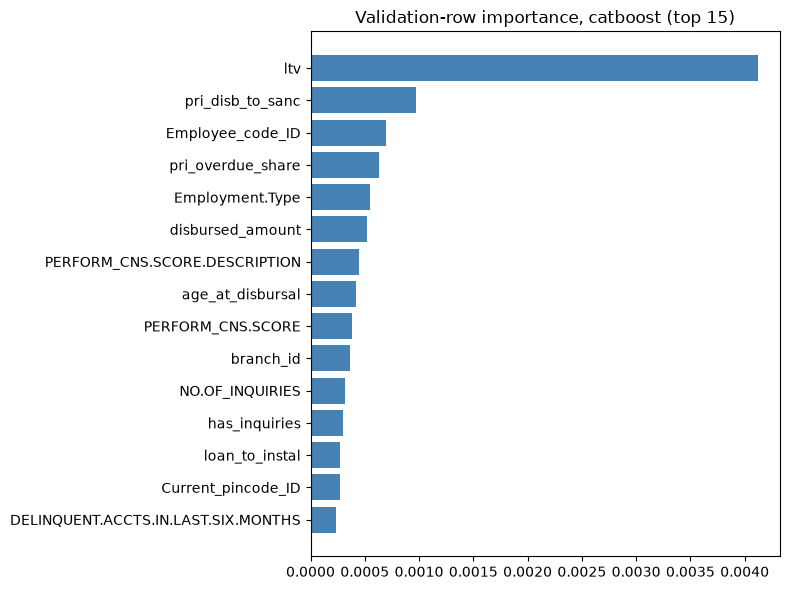

In [6]:
chosen_run = cv_cat if chosen_family == 'catboost' else cv_lgbm
imp_val = chosen_run['importance'].sort_values(ascending=False)
print(f'{chosen_family}: '
      f'{"LossFunctionChange" if chosen_family == "catboost" else "permutation AUC drop"} on validation rows')
print(imp_val.round(6).head(15).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
s = imp_val.head(15).sort_values()
ax.barh(s.index, s.values, color='steelblue')
ax.set_title(f'Validation-row importance, {chosen_family} (top 15)')
plt.tight_layout()
plt.show()

## 5. Final models

For each recipe: fit on the train rows dated before 18 Oct with early stopping on the rows dated 18–22 Oct (giving *n*), then train a new model with *n* trees on **all** train rows (LightGBM pooling levels refitted on all train).

In [7]:
final_lgbm = final_procedure('lightgbm', LGBM_FEATS)
final_cat = final_procedure('catboost', CAT_FEATS)
final_ctrl = final_procedure('lightgbm', CONTROL_FEATS)
for name, f in [('lightgbm', final_lgbm), ('catboost', final_cat), ('control', final_ctrl)]:
    print(f'{name:9s} n_trees={f["n_trees"]:5d}  fit rows {f["n_fit_rows"]:,}  held-back rows {f["n_held_rows"]:,}')

d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Default metric period is 5 because AUC is/are not implemented for GPU
Default metric period is 5 because AUC is/are not implemented for GPU
d:\WEBSITES\L&T loan default\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


lightgbm  n_trees=  257  fit rows 166,017  held-back rows 16,484
catboost  n_trees=  707  fit rows 166,017  held-back rows 16,484
control   n_trees=  344  fit rows 166,017  held-back rows 16,484


## 6. Save

`oof_predictions.csv` covers the validation rows only (1 Sep – 22 Oct) and carries the validation block.

In [8]:
import joblib

MODELS = DATA / 'models'
MODELS.mkdir(exist_ok=True)
joblib.dump(final_lgbm['model'], MODELS / 'lightgbm_final.joblib')
final_cat['model'].save_model(str(MODELS / 'catboost_final.cbm'))
joblib.dump(final_ctrl['model'], MODELS / 'control_final.joblib')


def level_lists(levels):
    return {c: [int(v) for v in lv] for c, lv in levels.items()}


(MODELS / 'pooling_levels.json').write_text(json.dumps(
    {'lightgbm': level_lists(final_lgbm['levels']), 'control': level_lists(final_ctrl['levels'])}, indent=2))

held_def = ('train rows dated 18-22 Oct 2018 (early stopping); the final model is then trained on all train rows')
(MODELS / 'final_models.json').write_text(json.dumps({
    name: {'family': fam, 'features': f['features'],
           'categorical_features': [c for c in f['features'] if c in CATEGORICAL],
           'n_features': len(f['features']), 'n_trees': f['n_trees'], 'held_back': held_def,
           'n_train_rows': f['n_scope_rows'], 'n_fit_rows': f['n_fit_rows'], 'n_held_rows': f['n_held_rows'],
           'file': file}
    for name, fam, f, file in [('lightgbm', 'lightgbm', final_lgbm, 'lightgbm_final.joblib'),
                               ('catboost', 'catboost', final_cat, 'catboost_final.cbm'),
                               ('control', 'lightgbm', final_ctrl, 'control_final.joblib')]}, indent=2))


def cv_json(r):
    return {'family': r['family'], 'features': r['features'], 'n_features': r['n_features'],
            'fold_auc': [float(a) for a in r['fold_auc']], 'mean_auc': r['mean_auc'], 'se': r['se'],
            'pooled_auc': r['pooled_auc'], 'n_trees': r['n_trees']}


cv_results = {
    'strategy': STRATEGY, 'mode': 'estimation',
    'lightgbm': cv_json(cv_lgbm), 'catboost': cv_json(cv_cat), 'control': cv_json(cv_ctrl),
    'choice': choice,
    'validation_importance': {
        'lightgbm': {c: float(v) for c, v in cv_lgbm['importance'].items()},
        'catboost': {c: float(v) for c, v in cv_cat['importance'].items()},
        'chosen_family': chosen_family,
        'metric': {'lightgbm': 'permutation AUC drop (<= 6000 validation rows per fold, 3 repeats)',
                   'catboost': 'LossFunctionChange on validation rows'},
    },
}
(DATA / 'cv_results.json').write_text(json.dumps(cv_results, indent=2))

fold_of = np.full(len(y), -1, dtype='int8')
for k, (_, _, val) in enumerate(FOLDS):
    fold_of[val] = k
in_val = fold_of >= 0
oof = pd.DataFrame({ID_COL: data[ID_COL], 'fold': fold_of, 'validation_block': fold_of + 1, TARGET: y,
                    'p_lightgbm': cv_lgbm['oof'], 'p_catboost': cv_cat['oof'], 'p_control': cv_ctrl['oof']})
oof[in_val].to_csv(DATA / 'oof_predictions.csv', index=False)
for f in ['cv_results.json', 'oof_predictions.csv', 'models/lightgbm_final.joblib', 'models/catboost_final.cbm',
          'models/control_final.joblib', 'models/pooling_levels.json', 'models/final_models.json']:
    print('Wrote', DATA / f)

Wrote ..\Data\Processed_time_cv\cv_results.json
Wrote ..\Data\Processed_time_cv\oof_predictions.csv
Wrote ..\Data\Processed_time_cv\models\lightgbm_final.joblib
Wrote ..\Data\Processed_time_cv\models\catboost_final.cbm
Wrote ..\Data\Processed_time_cv\models\control_final.joblib
Wrote ..\Data\Processed_time_cv\models\pooling_levels.json
Wrote ..\Data\Processed_time_cv\models\final_models.json
